# The Hyperliquid BTC order book at four resolutions

[![CI](https://github.com/hypernatt/hyperliquid-l2-notebooks/actions/workflows/ci.yml/badge.svg)](https://github.com/hypernatt/hyperliquid-l2-notebooks/actions/workflows/ci.yml) [![DOI](https://zenodo.org/badge/DOI/10.5281/zenodo.24151403.svg)](https://doi.org/10.5281/zenodo.24151403) [![Data licence: CC BY 4.0](https://img.shields.io/badge/data-CC%20BY%204.0-2a78d6)](https://creativecommons.org/licenses/by/4.0/) [![Code licence: MIT](https://img.shields.io/badge/code-MIT-2a78d6)](https://github.com/hypernatt/hyperliquid-l2-notebooks/blob/main/LICENSE) [![Hugging Face: sample](https://img.shields.io/badge/Hugging%20Face-sample-2a78d6)](https://huggingface.co/datasets/hypernatt/hyperliquid-l2-sample)

Hyperliquid's public `l2Book` stream returns 20 price levels per side. The same stream can be subscribed with a
coarser price grid, and each grid again returns 20 levels: a fine grid shows the book close to the mid in detail,
a coarse grid shows it farther away with less detail. The [HyperNatt archive](https://hypernatt.com/datasets)
records four of these views side by side.

This notebook works on the free 24-hour sample of that archive (BTC, one UTC day) and asks four questions:

1. What does each view show?
2. Do the four views describe the same book?
3. What does the book look like once the four views are stitched into one depth curve?
4. What does that curve say about the cost of a market order, and how does it compare with the orders that were
   executed that day?

It is a description of one day of data, not trading advice. The text of this notebook contains no result: every
number is computed and printed by the cell that follows. The functions live in [`hlbook.py`](../hlbook.py) and
the figures in [`hlplots.py`](../hlplots.py).

## 0. The data

The sample is downloaded once and checked against the SHA-256 published in `release.json`. If the file on disk is
not the published file, the notebook stops here.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "hlbook.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import hlbook
import hlplots

hlplots.use_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
RESULTS = ROOT / "results"
SUMMARY = {}

In [2]:
release = hlbook.fetch_release()
zip_path = hlbook.download_sample(release, ROOT / "data")      # verifies size and SHA-256, raises if they differ
sha256 = hlbook.sha256_file(zip_path)
sample = hlbook.Sample(zip_path)
DAY = release["sample"]["day"]

print("release  ", release["release_id"])
print("file     ", zip_path.name, f"({zip_path.stat().st_size:,} bytes)")
print("SHA-256  ", sha256)
print("         ", "identical to release.json" if sha256 == release["sample"]["sha256"] else "DIFFERENT")
print("DOI      ", hlbook.SAMPLE_DOI)
print("licence  ", release["sample"]["licence"])
print("streams  ", ", ".join(sample.streams()))

SUMMARY["release"] = {"release_id": release["release_id"], "day": DAY, "filename": zip_path.name,
                      "bytes": zip_path.stat().st_size, "sha256": sha256, "licence": release["sample"]["licence"],
                      "doi": hlbook.SAMPLE_DOI}

release   20261110
file      HYPERNATT_HL_L2_BTC_SAMPLE_20260911.zip (88,487,924 bytes)
SHA-256   128aa6beaff2aa294a3d711f810744977c46ee2eac4c1d9f9f80405e0c24df03
          identical to release.json
DOI       10.5281/zenodo.24151403
licence   CC-BY-4.0
streams   CANDLES, FUNDING, bbo, l2Book_AGG4, l2Book_M2, l2Book_M5, l2Book_REF, trades


The archive ships its own continuity report, `CONTINUITY.json`: for each stream, the number of recorded messages,
the time between two messages and the longest silence of the day. The order-book views are pushed by the exchange
at a fixed pace of a few seconds; the best bid and offer and the trades arrive much faster.

In [3]:
continuity = sample.read_json("CONTINUITY.json")["streams"]
STREAMS = [f"l2Book_{v}" for v in hlbook.VIEWS] + ["bbo", "trades"]
cadence = pd.DataFrame({
    s: {"messages": continuity[s]["per_day"][DAY]["events"]["DATA"],
        "seconds between messages, median": continuity[s]["per_day"][DAY]["cadence_median_s"],
        "seconds between messages, 99th pct": continuity[s]["per_day"][DAY]["cadence_p99_s"],
        "longest silence, seconds": continuity[s]["per_day"][DAY]["max_silence_s"]}
    for s in STREAMS}).T
cadence["messages"] = cadence["messages"].astype(int)
SUMMARY["cadence"] = cadence.to_dict("index")
cadence

,messages,"seconds between messages, median","seconds between messages, 99th pct","longest silence, seconds"
l2Book_REF,16094,5.389,5.588,7.217
l2Book_M2,16093,5.389,5.587,7.888
l2Book_M5,16093,5.389,5.587,16.391
l2Book_AGG4,16095,5.389,5.587,8.163
bbo,583294,0.099,0.807,9.864
trades,113287,0.404,4.768,17.016


{'REF': '16,094 snapshots', 'M2': '16,093 snapshots', 'M5': '16,093 snapshots', 'AGG4': '16,095 snapshots'} | 583,294 BBO messages


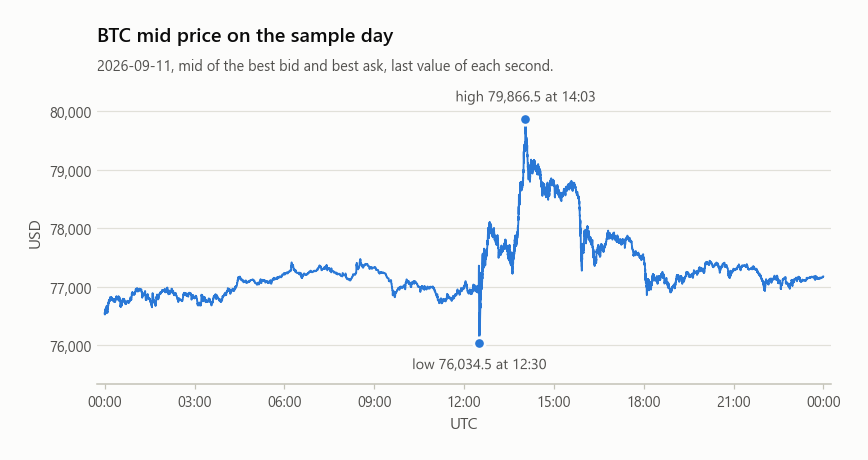

In [4]:
books = {v: hlbook.load_books(sample, v) for v in hlbook.VIEWS}
bbo = hlbook.load_bbo(sample)
print({v: f"{len(b):,} snapshots" for v, b in books.items()}, f"| {len(bbo):,} BBO messages")

fig = hlplots.day_mid(bbo, f"{DAY[:4]}-{DAY[4:6]}-{DAY[6:]}")
hlplots.save(fig, RESULTS / "00_day_mid.png")
plt.show()

## 1. What each view shows

`REF` is the book at the native price step. `M2`, `M5` and `AGG4` are the same book on coarser price grids (the
`nSigFigs` and `mantissa` parameters of the subscription, listed in the archive's `SCHEMA.md`). Each view returns
at most 20 levels per side, so a coarser grid reaches farther from the mid and gathers more size.

For every snapshot of the day, the table gives the price step of the view, how far its last level is from the
mid (in basis points), and how many BTC its levels hold on each side.

In [5]:
steps_usd = {v: hlbook.price_step(books[v]) / hlbook.PX_SCALE for v in hlbook.VIEWS}
reach = {v: hlbook.view_reach(books[v]) for v in hlbook.VIEWS}

rows = {}
for v in hlbook.VIEWS:
    r = reach[v]
    bid10, bid50, bid90 = hlbook.quantiles(r["btc_bid"])
    ask10, ask50, ask90 = hlbook.quantiles(r["btc_ask"])
    rows[v] = {"price step, USD": steps_usd[v], "snapshots": len(r),
               "reach bid, bps (median)": r["reach_bid_bps"].median(),
               "reach ask, bps (median)": r["reach_ask_bps"].median(),
               "BTC bid, 10th pct": bid10, "BTC bid, median": bid50, "BTC bid, 90th pct": bid90,
               "BTC ask, 10th pct": ask10, "BTC ask, median": ask50, "BTC ask, 90th pct": ask90}
views_table = pd.DataFrame(rows).T
views_table["snapshots"] = views_table["snapshots"].astype(int)
SUMMARY["views"] = views_table.to_dict("index")

first, last = views_table.loc[hlbook.VIEWS[0]], views_table.loc[hlbook.VIEWS[-1]]
print(f"Reading: the native view ({hlbook.VIEWS[0]}) ends {first['reach ask, bps (median)']:.1f} bps from the mid "
      f"and holds a median of {first['BTC bid, median']:.0f} BTC on the bid side and {first['BTC ask, median']:.0f} on the ask side.")
print(f"         The coarsest view ({hlbook.VIEWS[-1]}) ends {last['reach ask, bps (median)']:.1f} bps from the mid "
      f"and holds {last['BTC bid, median']:.0f} and {last['BTC ask, median']:.0f} BTC.")
views_table

Reading: the native view (REF) ends 2.7 bps from the mid and holds a median of 55 BTC on the bid side and 60 on the ask side.
         The coarsest view (AGG4) ends 25.3 bps from the mid and holds 641 and 656 BTC.


,"price step, USD",snapshots,"reach bid, bps (median)","reach ask, bps (median)","BTC bid, 10th pct","BTC bid, median","BTC bid, 90th pct","BTC ask, 10th pct","BTC ask, median","BTC ask, 90th pct"
REF,1.000,16094,2.544,2.652,29.580,55.012,100.639,31.504,60.272,112.230
M2,2.000,16093,5.059,5.061,112.504,163.138,226.379,113.844,173.568,241.230
M5,5.000,16093,12.637,12.638,334.944,420.337,508.642,337.969,435.637,527.838
AGG4,10.000,16095,25.274,25.274,538.162,640.861,749.908,542.702,656.171,786.355


The figure draws one snapshot, the same exchange time in the four views: the cumulative size from the best price
outwards, bids to the left and asks to the right. Each line stops where the 20 levels of its view stop.

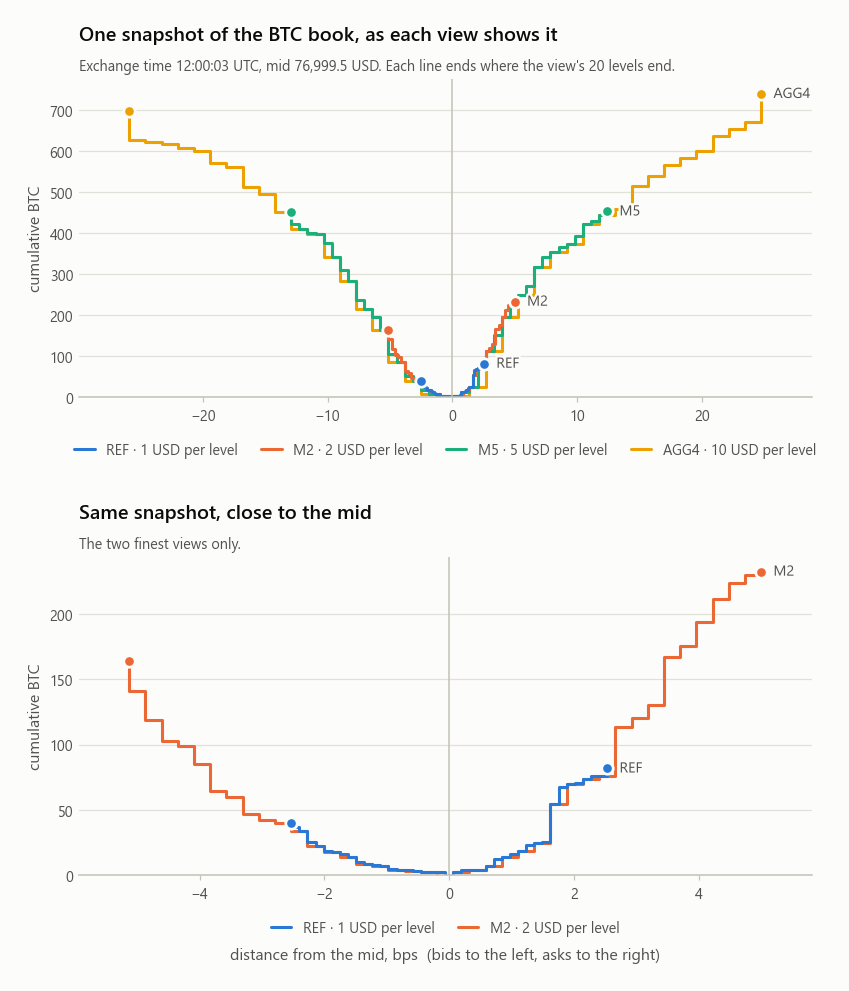

In [6]:
stamps = hlbook.common_times(books)
noon = int(pd.Timestamp(f"{DAY} 12:00", tz="UTC").timestamp() * 1000)
t_example = int(stamps[np.searchsorted(stamps, noon)])        # first snapshot at or after 12:00 UTC

fig = hlplots.one_snapshot(books, t_example, steps_usd)
hlplots.save(fig, RESULTS / "01_one_snapshot.png")
plt.show()

## 2. Do the four views describe the same book?

Each view is a separate subscription and arrives as a separate message. The exchange stamps every snapshot with
its own time. When two views carry the same exchange time, they should be two readings of one book: every
aggregated level should hold exactly the sum of the finer levels that fall into it.

Aggregation rounds bid prices down and ask prices up to the coarser grid (`hlbook.bucket_of`). The comparison
uses integers (1e-5 BTC), so "equal" means equal to the last recorded digit, and it only counts aggregated levels
that lie entirely inside the price range shown by the finer view.

In [7]:
PAIRS = [("REF", "M2"), ("REF", "M5"), ("M2", "AGG4"), ("M5", "AGG4")]
checks = pd.DataFrame([hlbook.cross_check(books[fine], books[coarse]) for fine, coarse in PAIRS])
checks.insert(0, "pair", checks["coarse"] + " against " + checks["fine"])
checks = checks.drop(columns=["coarse", "fine"]).set_index("pair")
checks["share equal, %"] = 100 * checks["levels_equal"] / checks["levels_tested"]

same_time = len(stamps) / max(len(b) for b in books.values())
SUMMARY["cross_check"] = {"pairs": checks.to_dict("index"), "levels_tested": int(checks["levels_tested"].sum()),
                          "levels_equal": int(checks["levels_equal"].sum()),
                          "largest_gap_btc": float(checks["largest_gap_btc"].max()),
                          "snapshots_same_time_4_views": len(stamps), "share_same_time_4_views": same_time}

print(f"Reading: {checks['levels_equal'].sum():,} of {checks['levels_tested'].sum():,} aggregated levels equal the sum "
      f"of their finer levels; largest gap {checks['largest_gap_btc'].max():g} BTC.")
print(f"         {len(stamps):,} snapshots carry the same exchange time in the four views "
      f"({100 * same_time:.1f} % of the snapshots of a view).")
checks.rename(columns={"coarse_step_usd": "coarse step, USD", "fine_step_usd": "fine step, USD",
                       "snapshots_same_time": "snapshots with the same time", "levels_tested": "levels compared",
                       "levels_equal": "levels equal", "largest_gap_btc": "largest gap, BTC"})

Reading: 908,878 of 908,878 aggregated levels equal the sum of their finer levels; largest gap 0 BTC.
         15,534 snapshots carry the same exchange time in the four views (96.5 % of the snapshots of a view).


,"coarse step, USD","fine step, USD",snapshots with the same time,levels compared,levels equal,"largest gap, BTC","share equal, %"
pair,,,,,,,
M2 against REF,2.000,1.000,15667,328213,328213,0.000,100.000
M5 against REF,5.000,1.000,15824,136060,136060,0.000,100.000
AGG4 against M2,10.000,2.000,15796,128408,128408,0.000,100.000
AGG4 against M5,10.000,5.000,15797,316197,316197,0.000,100.000


## 3. One depth curve from four views

When the views agree, each one gives exact points of the same curve: the size resting between the best price and
the far edge of each of its levels. The stitched curve uses the finest view as far as it reaches, then hands over
to the next one (`hlbook.stitch_side`). Its resolution decreases with the distance from the mid: the native step
first, then each coarser grid.

Inside the native view the curve is exact at every price. Farther out, the size of an aggregated level sits
somewhere between its two edges, so the size resting within a given distance of the mid is known between two
bounds ("at least", "at most"). Only snapshots whose exchange time is common to the four views are stitched.

In [8]:
st = hlbook.stitch(books)
DISTANCES = np.array([1.0, 2.5, 5.0, 10.0, 25.0])                       # bps from the mid
columns = {}
for side in ("bid", "ask"):
    low, high = hlbook.depth_within(st, DISTANCES, side)
    columns[f"{side}: at least, BTC (median)"] = hlbook.column_quantiles(low, [0.5])[0]
    columns[f"{side}: at most, BTC (median)"] = hlbook.column_quantiles(high, [0.5])[0]
    columns[f"{side}: snapshots covered, %"] = 100 * np.mean(~np.isnan(low), axis=0)
depth_table = pd.DataFrame(columns, index=[f"within {d:g} bps" for d in DISTANCES])
SUMMARY["depth"] = depth_table.to_dict("index")

ref_at = np.searchsorted(books["REF"].time, st.time)
native_btc = {s: reach["REF"][f"btc_{s}"].to_numpy()[ref_at] for s in ("bid", "ask")}
stitched_btc = {s: np.max(st.side(s)[1], axis=1) / hlbook.SZ_SCALE for s in ("bid", "ask")}
gain = float(np.median(np.concatenate([stitched_btc[s] / native_btc[s] for s in ("bid", "ask")])))
farther = float(np.median(np.concatenate([
    reach["AGG4"][f"reach_{s}_bps"].to_numpy()[np.searchsorted(books["AGG4"].time, st.time)]
    / reach["REF"][f"reach_{s}_bps"].to_numpy()[ref_at] for s in ("bid", "ask")])))
SUMMARY["stitched"] = {"snapshots": len(st), "btc_ratio_stitched_over_native_median": gain,
                       "reach_ratio_stitched_over_native_median": farther}

print(f"Reading: {len(st):,} stitched snapshots. In the median snapshot the stitched curve shows {gain:.1f} times "
      f"the BTC of the native view and reaches {farther:.1f} times farther from the mid.")
depth_table

Reading: 15,534 stitched snapshots. In the median snapshot the stitched curve shows 11.1 times the BTC of the native view and reaches 9.5 times farther from the mid.


,"bid: at least, BTC (median)","bid: at most, BTC (median)","bid: snapshots covered, %","ask: at least, BTC (median)","ask: at most, BTC (median)","ask: snapshots covered, %"
within 1 bps,12.578,12.578,100.000,13.211,13.211,100.000
within 2.5 bps,47.577,47.701,100.000,51.102,51.249,100.000
within 5 bps,154.361,166.319,100.000,163.098,176.071,100.000
within 10 bps,341.484,359.733,100.000,354.561,372.701,100.000
within 25 bps,616.123,646.763,69.480,636.157,666.538,66.062


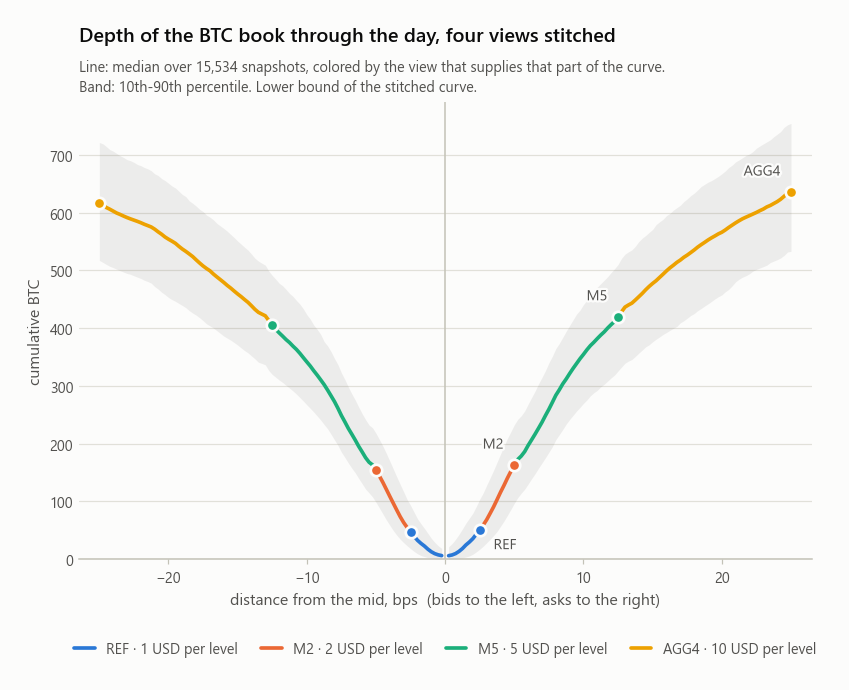

In [9]:
GRID = np.arange(0.25, 30.01, 0.25)
bands = {}
for side in ("bid", "ask"):
    low, _ = hlbook.depth_within(st, GRID, side)
    q10, q50, q90 = hlbook.column_quantiles(low)
    bands[side] = (q10, q50, q90, np.mean(~np.isnan(low), axis=0))
reach_median = {v: {s: float(reach[v][f"reach_{s}_bps"].median()) for s in ("bid", "ask")} for v in hlbook.VIEWS}

fig = hlplots.depth_day(GRID, bands, reach_median, steps_usd, len(st), min_cover=0.5)
hlplots.save(fig, RESULTS / "02_depth_day.png")
plt.show()

## 4. The cost of a market order

A market order walks the book from the best price outwards. On the stitched curve its average price is exact
while it stays inside the native view. Beyond, each aggregated level is priced twice: at its near edge (low bound)
and at its far edge (high bound). Costs are in basis points from the mid, so the smallest order costs half the
spread.

The last two columns say how often each size can be priced at all: with the four views stitched, and with the
native view alone.

In [10]:
SIZES = np.array([1.0, 5.0, 10.0, 25.0, 50.0, 100.0, 250.0, 500.0])     # BTC
cost = {side: hlbook.sweep_costs(st, SIZES, side) for side in ("ask", "bid")}   # (low, high) per side

native_ok = np.mean([(reach["REF"][f"btc_{s}"].to_numpy()[:, None] >= SIZES).mean(axis=0) for s in ("bid", "ask")], axis=0)
stitched_ok = np.mean([np.mean(~np.isnan(cost[s][1]), axis=0) for s in ("bid", "ask")], axis=0)
cost_table = pd.DataFrame({
    "buy: low, bps": hlbook.column_quantiles(cost["ask"][0], [0.5])[0],
    "buy: high, bps": hlbook.column_quantiles(cost["ask"][1], [0.5])[0],
    "sell: low, bps": hlbook.column_quantiles(cost["bid"][0], [0.5])[0],
    "sell: high, bps": hlbook.column_quantiles(cost["bid"][1], [0.5])[0],
    "priceable, four views, %": 100 * stitched_ok, "priceable, native view alone, %": 100 * native_ok,
}, index=pd.Index([f"{s:g} BTC" for s in SIZES], name="order size"))
SUMMARY["cost"] = cost_table.to_dict("index")

native_limit = float(np.median(np.concatenate([reach["REF"]["btc_bid"], reach["REF"]["btc_ask"]])))
SUMMARY["native_limit_btc_median"] = native_limit
print(f"Reading: medians over {len(st):,} snapshots. The native view alone holds a median of {native_limit:.0f} BTC per side.")
cost_table

Reading: medians over 15,534 snapshots. The native view alone holds a median of 57 BTC per side.


,"buy: low, bps","buy: high, bps","sell: low, bps","sell: high, bps","priceable, four views, %","priceable, native view alone, %"
order size,,,,,,
1 BTC,0.065,0.065,0.065,0.065,100.000,99.984
5 BTC,0.065,0.065,0.065,0.065,100.000,99.845
10 BTC,0.318,0.318,0.308,0.308,100.000,99.500
25 BTC,0.876,0.876,0.900,0.900,100.000,94.573
50 BTC,1.445,1.446,1.514,1.516,100.000,61.821
100 BTC,2.234,2.283,2.332,2.387,100.000,12.868
250 BTC,3.973,4.180,4.131,4.352,99.881,0.183
500 BTC,7.129,7.552,7.483,7.943,95.851,0.000


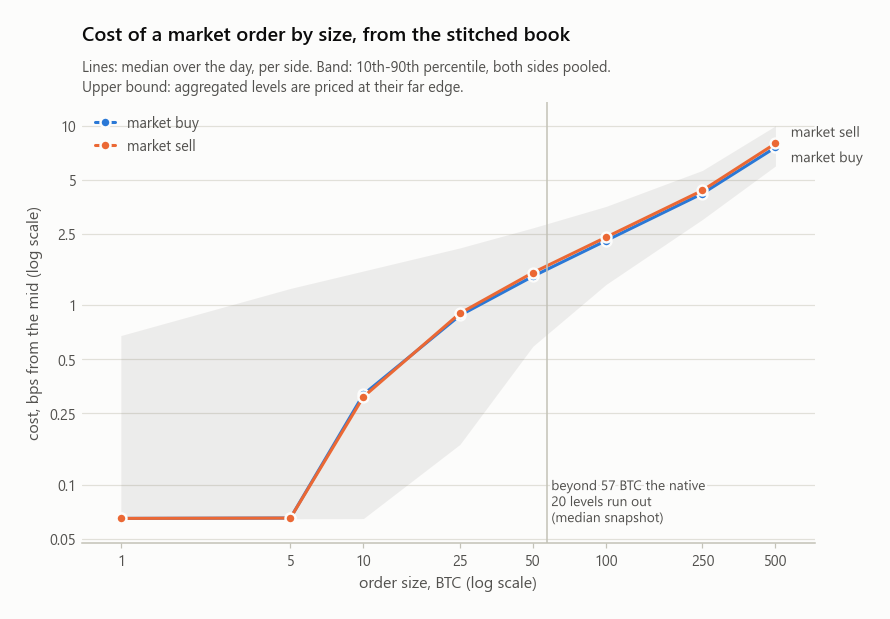

In [11]:
medians = {side: hlbook.column_quantiles(cost[side][1], [0.5])[0] for side in ("ask", "bid")}
q10, _, q90 = hlbook.column_quantiles(np.vstack([cost["ask"][1], cost["bid"][1]]))     # both sides pooled
fig = hlplots.cost_by_size(SIZES, medians, (q10, q90), native_limit)
hlplots.save(fig, RESULTS / "03_cost_by_size.png")
plt.show()

The same cost, hour by hour: for each hour of the day and each size, the median over the snapshots of that hour
(high bound, mean of buy and sell). The table gives the cost in basis points. The figure divides each row by its
own median over the day, to show when the book was thinner or deeper than usual for every size at once.

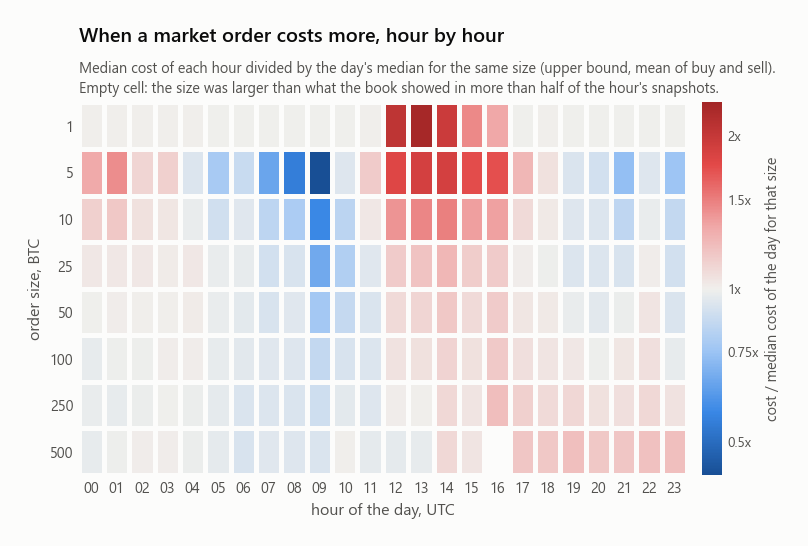

"hour, UTC",0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
"order size, BTC",,,,,,,,,,,,,,,,,,,,,
1,0.070,0.070,0.070,0.070,0.060,0.060,0.060,0.060,0.060,0.060,...,0.130,0.090,0.090,0.060,0.060,0.060,0.060,0.060,0.060,0.060
5,0.350,0.390,0.300,0.300,0.250,0.210,0.240,0.180,0.150,0.120,...,0.510,0.470,0.460,0.340,0.290,0.250,0.240,0.200,0.250,0.200
10,0.570,0.590,0.530,0.520,0.490,0.450,0.480,0.420,0.400,0.290,...,0.750,0.680,0.680,0.550,0.510,0.470,0.470,0.430,0.490,0.430
25,1.030,1.030,1.040,1.020,1.030,0.980,0.980,0.910,0.920,0.670,...,1.260,1.150,1.160,1.010,1.000,0.940,0.940,0.920,1.010,0.900
50,1.570,1.580,1.570,1.580,1.590,1.530,1.510,1.450,1.480,1.210,...,1.830,1.700,1.810,1.630,1.600,1.530,1.490,1.540,1.640,1.460
100,2.310,2.350,2.350,2.390,2.400,2.310,2.260,2.240,2.230,2.020,...,2.650,2.500,2.740,2.530,2.480,2.450,2.350,2.460,2.520,2.300
250,4.150,4.150,4.190,4.240,4.200,4.100,3.950,3.990,3.950,3.810,...,4.670,4.450,5.190,4.820,4.630,4.700,4.510,4.550,4.660,4.490
500,7.430,7.540,7.690,7.710,7.510,7.380,7.050,7.220,7.170,7.080,...,8.340,7.990,NaN,8.980,8.930,9.220,8.910,9.000,9.180,9.220


In [12]:
hour = (st.time // 3_600_000) % 24
both = (cost["ask"][1] + cost["bid"][1]) / 2                             # NaN when one side cannot be priced
hourly = pd.DataFrame(index=pd.Index([f"{s:g}" for s in SIZES], name="order size, BTC"),
                      columns=pd.Index(range(24), name="hour, UTC"), dtype=float)
for h in range(24):
    block = both[hour == h]
    priced = np.mean(~np.isnan(block), axis=0)
    hourly[h] = np.where(priced >= 0.5, hlbook.column_quantiles(block, [0.5])[0], np.nan)
SUMMARY["cost_by_hour"] = {"sizes_btc": SIZES.tolist(), "hours_utc": list(range(24)), "bps": hourly.to_numpy().tolist()}

ratio = hourly.div(hourly.median(axis=1), axis=0).set_axis(SIZES, axis=0)
fig = hlplots.cost_by_hour(ratio)
hlplots.save(fig, RESULTS / "04_cost_by_hour.png")
plt.show()
hourly.round(2)

## 5. The orders that were executed

The `trades` stream lists every fill. Fills that share a transaction hash and a side are grouped here into one
taker order; this is an approximation of "one order". Fills that carry the all-zero hash are not tied to one
transaction: they are counted, then left out.

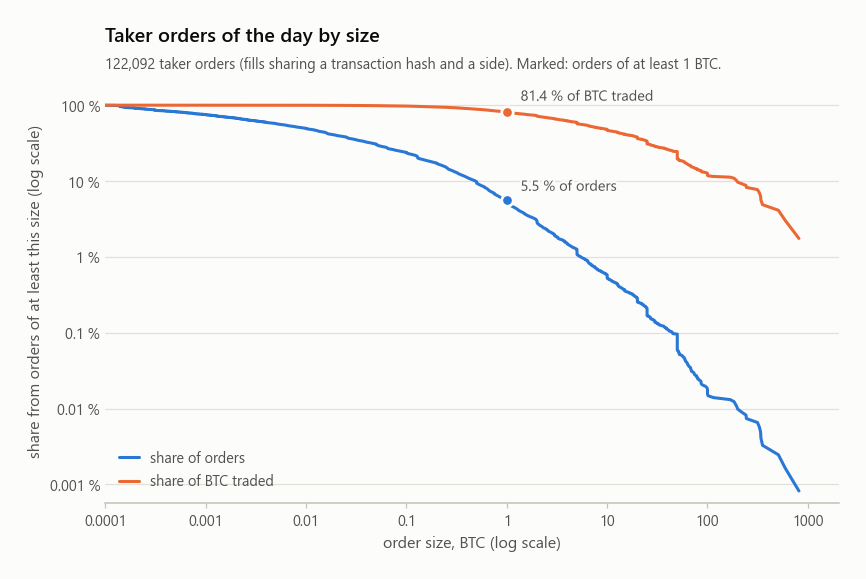

,value
fills,"364,264.000"
BTC traded,"47,644.624"
fills with the all-zero hash,"42,627.000"
BTC in those fills,"1,017.372"
taker orders,"122,092.000"
"order size, median, BTC",0.009
"order size, 90th pct, BTC",0.486
"order size, 99th pct, BTC",5.433
"order size, 99.9th pct, BTC",44.455
"largest order, BTC",815.119


In [13]:
trades = hlbook.load_trades(sample)
orders = hlbook.taker_orders(trades)
q50, q90, q99, q999 = hlbook.quantiles(orders["size"], (0.5, 0.9, 0.99, 0.999))
orders_stats = {
    "fills": len(trades), "BTC traded": float(trades["sz"].sum()),
    "fills with the all-zero hash": orders.attrs["zero_hash_fills"], "BTC in those fills": orders.attrs["zero_hash_btc"],
    "taker orders": len(orders), "order size, median, BTC": q50, "order size, 90th pct, BTC": q90,
    "order size, 99th pct, BTC": q99, "order size, 99.9th pct, BTC": q999, "largest order, BTC": float(orders["size"].max()),
    "orders of at least 1 BTC": int((orders["size"] >= 1).sum()),
    "share of BTC traded by orders of at least 1 BTC, %": 100 * float(orders.loc[orders["size"] >= 1, "size"].sum() / orders["size"].sum()),
}
SUMMARY["orders"] = orders_stats

fig = hlplots.order_sizes(orders)
hlplots.save(fig, RESULTS / "05_order_sizes.png")
plt.show()
pd.Series(orders_stats, name="value").to_frame()

For every taker order of at least 1 BTC, two costs are put side by side:

- **realized**: the average fill price of the order against the mid of the last BBO before it;
- **book**: the cost of the same size on the last stitched snapshot before the order (chapter 4).

The two are not measured at the same instant: the stitched snapshot is a few seconds old when the order arrives
(its age is in the table), while the BBO is much more recent. The differences are reported as they are.

Reading: median realized cost minus median book cost (high bound), by size class, in bps:
         1-5: -0.00, 5-10: -0.04, 10-25: -0.09, 25-50: -0.32, 50-100: -0.11, 100+: -0.25
         Median age of the stitched snapshot when the order arrives: 2.8 s.


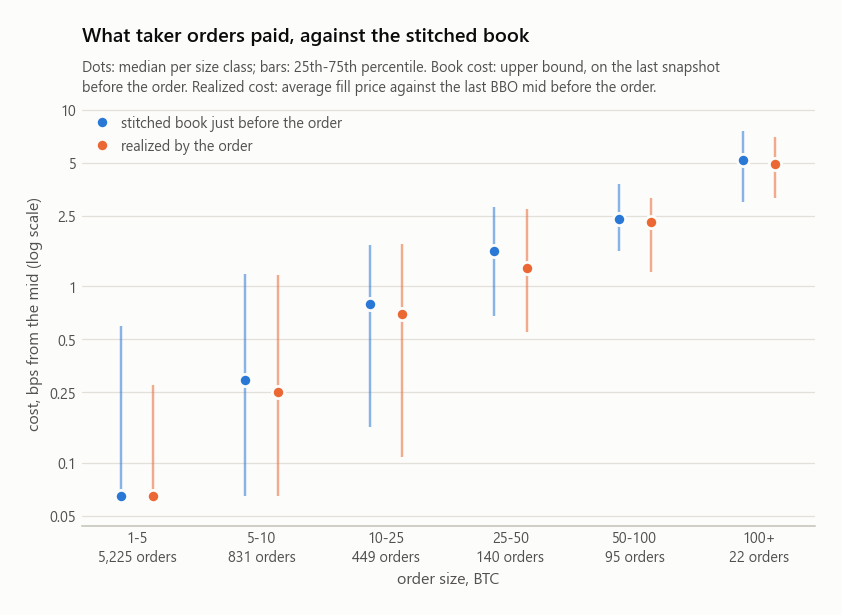

,orders,"realized, 25th pct","realized, median","realized, 75th pct","book low bound, median","book, 25th pct","book, median","book, 75th pct","priceable on the book, %","age of the book, s (median)"
"order size, BTC",,,,,,,,,,
1-5,5225,0.064,0.065,0.275,0.065,0.065,0.065,0.597,99.981,2.835
5-10,831,0.065,0.251,1.163,0.293,0.065,0.293,1.168,100.000,2.789
10-25,449,0.108,0.698,1.734,0.788,0.159,0.788,1.705,100.000,2.906
25-50,140,0.552,1.267,2.720,1.586,0.674,1.586,2.809,100.000,2.821
50-100,95,1.205,2.305,3.178,2.387,1.574,2.415,3.797,100.000,2.804
100+,22,3.172,4.943,6.985,4.933,2.992,5.196,7.542,90.909,3.700


In [14]:
large = orders[orders["size"] >= 1].reset_index(drop=True)
large = hlbook.book_cost_before(hlbook.realized_cost(large, bbo), st)
EDGES = [1, 5, 10, 25, 50, 100, np.inf]
LABELS = ["1-5", "5-10", "10-25", "25-50", "50-100", "100+"]
large["class"] = pd.cut(large["size"], EDGES, right=False, labels=LABELS)

groups = large.groupby("class", observed=True)
quantile = lambda q: (lambda x: x.quantile(q))
compare = groups.agg(
    orders=("size", "size"),
    realized_q25=("realized_bps", quantile(0.25)), realized_median=("realized_bps", "median"),
    realized_q75=("realized_bps", quantile(0.75)),
    book_low_median=("book_low_bps", "median"),
    book_q25=("book_high_bps", quantile(0.25)), book_median=("book_high_bps", "median"),
    book_q75=("book_high_bps", quantile(0.75)),
    book_priceable_pct=("book_high_bps", lambda x: 100 * x.notna().mean()),
    book_age_s_median=("book_age_s", "median"),
)
compare.index = compare.index.astype(str)
compare.index.name = "order size, BTC"
SUMMARY["realized_vs_book"] = compare.to_dict("index")

diff = (compare["realized_median"] - compare["book_median"])
print("Reading: median realized cost minus median book cost (high bound), by size class, in bps:")
print("        ", ", ".join(f"{k}: {v:+.2f}" for k, v in diff.items()))
print(f"         Median age of the stitched snapshot when the order arrives: {large['book_age_s'].median():.1f} s.")

fig = hlplots.realized_vs_book(compare)
hlplots.save(fig, RESULTS / "06_realized_vs_book.png")
plt.show()
compare.rename(columns={
    "realized_q25": "realized, 25th pct", "realized_median": "realized, median", "realized_q75": "realized, 75th pct",
    "book_low_median": "book low bound, median", "book_q25": "book, 25th pct", "book_median": "book, median",
    "book_q75": "book, 75th pct", "book_priceable_pct": "priceable on the book, %",
    "book_age_s_median": "age of the book, s (median)"})

## 6. Limits

- One UTC day, one coin. Nothing here says how the same measures behave on other days or on other coins.
- Each view returns at most 20 levels per side. Size resting beyond the coarsest view is not in the data.
- The order-book views are snapshots pushed every few seconds (see the continuity table in chapter 0); what
  happens between two snapshots is only visible through the best bid and offer and the trades.
- The public stream carries no sequence number. Chapter 2 shows that views with the same exchange time agree;
  it does not prove that no update was missed.
- Only snapshots whose exchange time is common to the four views are stitched (their share is printed in
  chapter 2).
- Beyond the native view, costs are bounds, not exact prices.
- Chapter 5 compares two different instants (a book a few seconds old, an order that executes later). The gap
  between the two columns mixes that delay with everything else.
- This is a description of recorded data. It is not trading advice.

The full archive has the same format for BTC and ETH: <https://hypernatt.com/datasets>.

In [15]:
RESULTS.mkdir(exist_ok=True)
(RESULTS / "summary.json").write_text(json.dumps(hlbook.rounded(SUMMARY), indent=2, sort_keys=True) + "\n",
                                      encoding="utf-8", newline="\n")
print("results/summary.json written.")

results/summary.json written.
